# Bab 4 – Membangun Model dengan Metrik Jarak dan Nearest Neighbors

## Ringkasan Bab
Jarak adalah inti dari banyak algoritma. Bab ini memperkenalkan **metrik jarak** (Euclidean, Manhattan, Minkowski,
Chebyshev, cosine, Hamming), algoritma **K-Nearest Neighbors (KNN)**, cara **menyetel** hyperparameternya
(`n_neighbors`, `weights`, `metric`), dan cara **mengevaluasinya**, lengkap dengan tiga latihan praktik.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, learning_curve
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)
from sklearn.metrics.pairwise import pairwise_distances

## 1. Pengantar Metrik Jarak
Sebuah **metrik** d(a,b) harus memenuhi empat syarat: tidak negatif, d = 0 hanya jika kedua titik sama, simetris, dan memenuhi ketaksamaan segitiga.

In [2]:
a, b = np.array([[1., 2., 3.]]), np.array([[4., 0., 3.]])
for m in ["euclidean", "manhattan", "chebyshev", "cosine"]:
    print(f"{m:10s}: {pairwise_distances(a, b, metric=m)[0,0]:.4f}")
print("minkowski p=3:", pairwise_distances(a, b, metric="minkowski", p=3)[0, 0].round(4))

euclidean : 3.6056
manhattan : 5.0000
chebyshev : 3.0000
cosine    : 0.3051
minkowski p=3: 3.2711


## 2. Memahami KNN
KNN adalah algoritma **non-parametrik berbasis instance (lazy learner)**: `fit` hanya menyimpan data. Untuk memprediksi sebuah titik:
1. hitung jaraknya ke semua data latih,
2. ambil **k tetangga terdekat**,
3. klasifikasi → **suara terbanyak** (bisa dibobot dengan jarak); regresi → **rata-rata** target para tetangga.

*k kecil* → bias rendah, varians tinggi (overfitting). *k besar* → bias tinggi, batas keputusan lebih halus (underfitting).

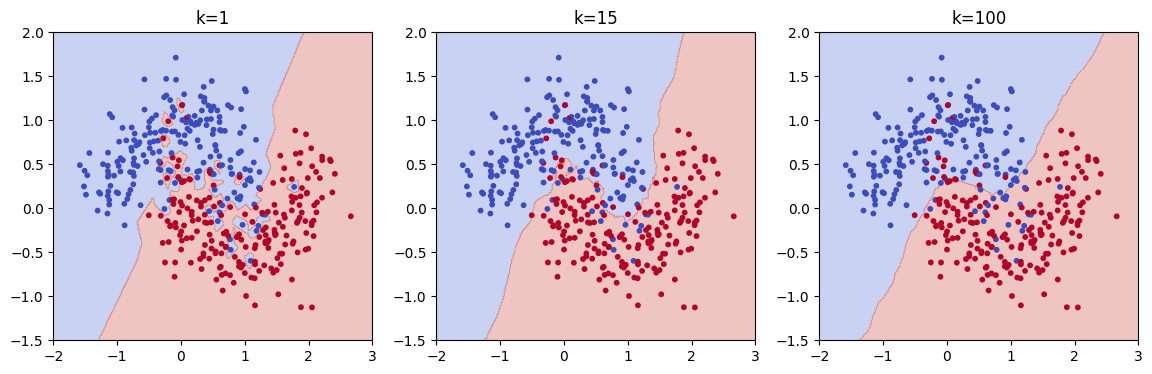

In [3]:
X, y = make_moons(n_samples=400, noise=0.3, random_state=0)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
for a_, k in zip(ax, [1, 15, 100]):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X, y)
    a_.contourf(xx, yy, knn.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), alpha=.3, cmap="coolwarm")
    a_.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=10); a_.set_title(f"k={k}")
plt.show()

## 3. Ringkasan Metrik Jarak
| Metrik | Rumus | Catatan |
|---|---|---|
| Euclidean (p=2) | √Σ(xᵢ−yᵢ)² | default, peka terhadap skala |
| Manhattan (p=1) | Σ\|xᵢ−yᵢ\| | lebih tahan outlier, baik di dimensi tinggi |
| Minkowski | (Σ\|xᵢ−yᵢ\|ᵖ)^(1/p) | bentuk umum dari keduanya |
| Chebyshev | maxᵢ\|xᵢ−yᵢ\| | selisih koordinat terbesar |
| Cosine | 1 − x·y/(‖x‖‖y‖) | melihat arah, bukan besar vektor (cocok untuk teks) |
| Hamming | proporsi elemen yang berbeda | data kategorikal/biner |

**Fitur harus di-scale dulu sebelum memakai model berbasis jarak.** Kalau tidak, fitur dengan rentang terbesar akan mendominasi.

In [4]:
Xc, yc = load_breast_cancer(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=42)
raw = KNeighborsClassifier().fit(Xtr, ytr)
scaled = make_pipeline(StandardScaler(), KNeighborsClassifier()).fit(Xtr, ytr)
print("Without scaling:", round(raw.score(Xte, yte), 3), "| With scaling:", round(scaled.score(Xte, yte), 3))
for m in ["euclidean", "manhattan", "chebyshev", "cosine"]:
    p = make_pipeline(StandardScaler(), KNeighborsClassifier(metric=m, algorithm="brute")).fit(Xtr, ytr)
    print(f"{m:10s} acc = {p.score(Xte, yte):.3f}")

Without scaling: 0.93 | With scaling: 0.979
euclidean  acc = 0.979
manhattan  acc = 0.965
chebyshev  acc = 0.930
cosine     acc = 0.965


## 4. Menyetel Hyperparameter KNN
Hyperparameter utamanya: `n_neighbors` (k), `weights` (`uniform` atau `distance`), `metric`/`p`,
dan `algorithm` (`brute`, `kd_tree`, `ball_tree`, yang hanya memengaruhi kecepatan, bukan akurasi).

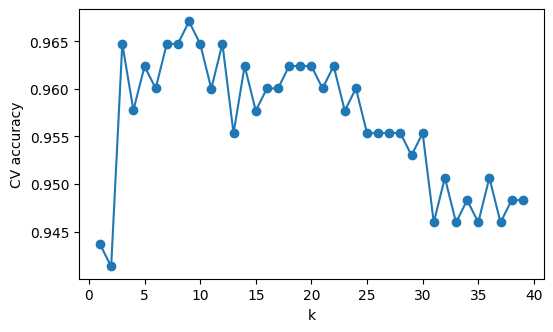

Best k: 9


In [5]:
ks = range(1, 40)
cv = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), Xtr, ytr, cv=5).mean() for k in ks]
plt.figure(figsize=(6, 3.5)); plt.plot(ks, cv, marker="o"); plt.xlabel("k"); plt.ylabel("CV accuracy"); plt.show()
print("Best k:", list(ks)[int(np.argmax(cv))])

## 5. Mengevaluasi Performa KNN
Selain akurasi, gunakan **confusion matrix**, **precision / recall / F1**, **ROC-AUC**, dan **learning curve**
untuk mendiagnosis masalah bias dan varians.

              precision    recall  f1-score   support

   malignant       1.00      0.94      0.97        53
      benign       0.97      1.00      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.97      0.98       143
weighted avg       0.98      0.98      0.98       143



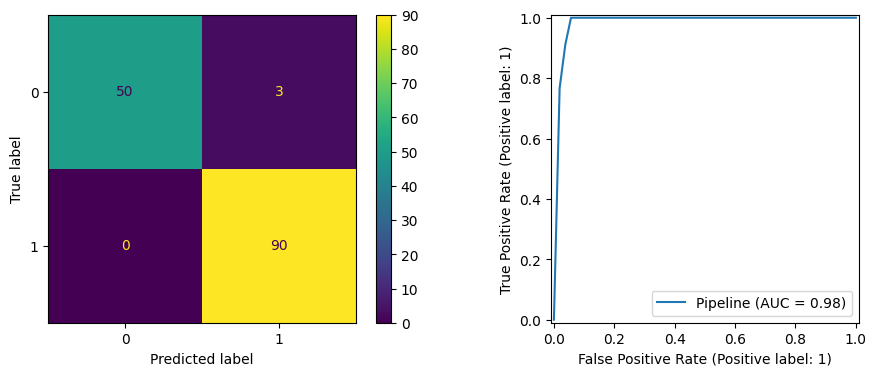

In [6]:
y_pred = scaled.predict(Xte)
print(classification_report(yte, y_pred, target_names=load_breast_cancer().target_names))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(yte, y_pred, ax=ax[0]); RocCurveDisplay.from_estimator(scaled, Xte, yte, ax=ax[1])
plt.show()

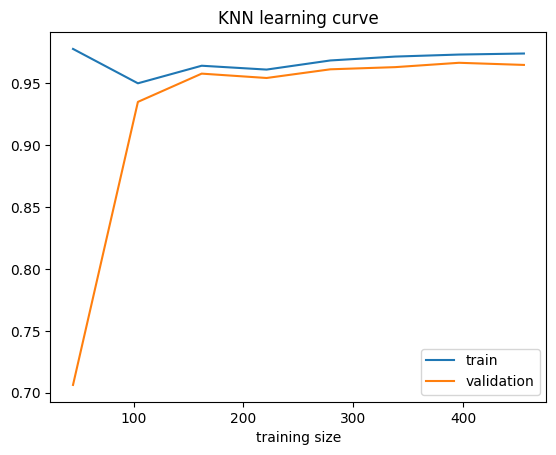

In [7]:
sizes, tr, va = learning_curve(scaled, Xc, yc, cv=5, train_sizes=np.linspace(.1, 1, 8))
plt.plot(sizes, tr.mean(1), label="train"); plt.plot(sizes, va.mean(1), label="validation")
plt.legend(); plt.xlabel("training size"); plt.title("KNN learning curve"); plt.show()

## 6. Latihan Praktik Model KNN

### Latihan 1 – Membangun Classifier KNN

In [8]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xtr, ytr)
print("Test accuracy:", round(knn.score(Xte, yte), 3))
print("Predicted probabilities (first 3):\n", knn.predict_proba(Xte[:3]).round(2))

Test accuracy: 0.979
Predicted probabilities (first 3):
 [[0.  1. ]
 [1.  0. ]
 [0.2 0.8]]


### Latihan 2 – Menyetel Hyperparameter dengan Grid Search

In [9]:
grid = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                    {"kneighborsclassifier__n_neighbors": range(1, 31, 2),
                     "kneighborsclassifier__weights": ["uniform", "distance"],
                     "kneighborsclassifier__p": [1, 2]}, cv=5, n_jobs=-1).fit(Xtr, ytr)
print("Best:", grid.best_params_, "| CV acc:", round(grid.best_score_, 3), "| test acc:", round(grid.score(Xte, yte), 3))
pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score"]].head()

Best: {'kneighborsclassifier__n_neighbors': 9, 'kneighborsclassifier__p': 2, 'kneighborsclassifier__weights': 'uniform'} | CV acc: 0.967 | test acc: 0.965


,params,mean_test_score
18,"{'kneighborsclassifier__n_neighbors': 9, 'knei...",0.967086
19,"{'kneighborsclassifier__n_neighbors': 9, 'knei...",0.967086
9,"{'kneighborsclassifier__n_neighbors': 5, 'knei...",0.964761
8,"{'kneighborsclassifier__n_neighbors': 5, 'knei...",0.964761
39,"{'kneighborsclassifier__n_neighbors': 19, 'kne...",0.964761


### Latihan 3 – Mengevaluasi Classifier KNN
Bandingkan model hasil penyetelan dengan model default menggunakan ROC-AUC hasil cross-validation.

In [10]:
for name, m in [("default", knn), ("tuned", grid.best_estimator_)]:
    s = cross_val_score(m, Xc, yc, cv=10, scoring="roc_auc")
    print(f"{name:8s} ROC-AUC = {s.mean():.4f} ± {s.std():.4f}")

default  ROC-AUC = 0.9892 ± 0.0121
tuned    ROC-AUC = 0.9897 ± 0.0117


**Kesimpulan:** KNN sederhana dan cukup kuat untuk data kecil yang sudah di-scale, tetapi lambat saat prediksi dan kurang baik
di dimensi tinggi (lihat Bab 3).